# Decision

Which complaints a team should review first, and what the text adds to that list. The scores are the ones the last notebook saved: out-of-fold for the training complaints and from the one test run for the test complaints. The test set isn't scored again, and the one thing fitted here, a rescaling of the scores, is fitted on train. The notebook takes about a minute to run.

In [1]:
import sys

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from src.data import load_text, time_split

FIGURES = "../reports/figures/"

In [2]:
train = pd.read_csv("../data/scored_train.csv")
test = pd.read_csv("../data/scored_test.csv")
y_train, y_test = train["disputed"].to_numpy(), test["disputed"].to_numpy()

MODELS = ["fields", "text", "both"]
LABELS = {"fields": "fields", "text": "text", "both": "fields and text score"}
test.shape, y_test.sum(), y_test.mean()

((37405, 8), np.int64(7795), np.float64(0.20839459965245288))

## Riskiest complaints first

A team can't review every complaint, so the scores are used as a ranking. The complaints with the highest scores are reviewed first, as far down the list as the team has time for, and a dispute counts as caught when its complaint was among the reviewed ones. The chart has the share of all disputes caught for each share reviewed, for the three models from the last notebook. The dotted line is at 10%, the share used in the rest of this notebook. That 10% is an assumption about how much a team can review, and nothing is tuned to it.

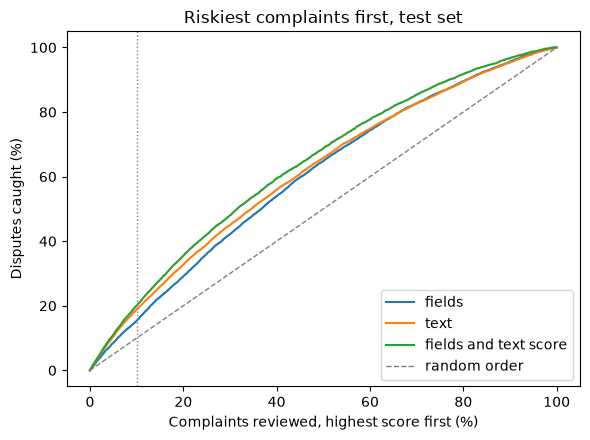

In [3]:
share_reviewed = np.arange(1, len(test) + 1) / len(test) * 100

fig, ax = plt.subplots(figsize=(6, 4.5))
for name in MODELS:
    order = np.argsort(-test[name].to_numpy(), kind="stable")
    ax.plot(share_reviewed, np.cumsum(y_test[order]) / y_test.sum() * 100, label=LABELS[name])
ax.plot([0, 100], [0, 100], color="grey", linestyle="--", linewidth=1, label="random order")
ax.axvline(10, color="grey", linestyle=":", linewidth=1)
ax.set_xlabel("Complaints reviewed, highest score first (%)")
ax.set_ylabel("Disputes caught (%)")
ax.set_title("Riskiest complaints first, test set")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES + "gains_curve.png", dpi=150)
plt.show()

In [4]:
def top(scores, share):
    flagged = np.zeros(len(scores), dtype=bool)
    flagged[np.argsort(-np.asarray(scores), kind="stable")[:int(len(scores) * share)]] = True
    return flagged


def reviewed(y, flagged):
    caught = y[flagged].sum()
    return {"reviewed": flagged.sum(), "disputes_caught": caught, "share_of_disputes": caught / y.sum(),
            "disputed_among_reviewed": caught / flagged.sum(), "lift": caught / flagged.sum() / y.mean()}


rows = {}
for share in [0.1, 0.2, 0.3]:
    for name in MODELS:
        rows[(f"top {int(share * 100)}%", name)] = reviewed(y_test, top(test[name], share))
pd.DataFrame(rows).T.astype({"reviewed": int, "disputes_caught": int}).round(3)

reviewed  disputes_caught  share_of_disputes  \
top 10% fields      3740             1199              0.154   
        text        3740             1468              0.188   
        both        3740             1564              0.201   
top 20% fields      7481             2267              0.291   
        text        7481             2549              0.327   
        both        7481             2768              0.355   
top 30% fields     11221             3286              0.422   
        text       11221             3507              0.450   
        both       11221             3740              0.480   

                disputed_among_reviewed   lift  
top 10% fields                    0.321  1.538  
        text                      0.393  1.884  
        both                      0.418  2.007  
top 20% fields                    0.303  1.454  
        text                      0.341  1.635  
        both                      0.370  1.775  
top 30% fields                    0.293  1.405  
        text                      0.313  1.500  
        both                      0.333  1.599

The top 10% is 3,740 of the 37,405 test complaints. With the fields 1,199 of them were disputed (32.1%), with the text 1,468 (39.3%) and with both 1,564 (41.8%). A random 10% would hold about 780 disputes, so the combined list is at 2.0 times random and the fields list at 1.5.

The text adds 365 disputes to the top 10%, about 98 more for every 1,000 complaints reviewed, and the combined list has 96 more than the text alone. The order of the three models is the same at 20% and 30%, where the combined model catches 35.5% and 48.0% of all disputes against 29.1% and 42.2% for the fields.

In [5]:
pd.DataFrame({name: reviewed(y_train, top(train[name], 0.1)) for name in MODELS}).T.astype(
    {"reviewed": int, "disputes_caught": int}).round(3)

,reviewed,disputes_caught,share_of_disputes,disputed_among_reviewed,lift
fields,11225,4101,0.157,0.365,1.572
text,11225,4957,0.190,0.442,1.900
both,11225,5218,0.200,0.465,2.000


The out-of-fold scores on train give the same picture. 36.5%, 44.2% and 46.5% of the top 10% were disputed, which is 1.57, 1.90 and 2.00 times the train rate. On test the three are at 1.54, 1.88 and 2.01, so the lift held in the later months even though the dispute rate fell.

### What the text changes in the top 10%

In [6]:
top_fields, top_both = top(test["fields"], 0.1), top(test["both"], 0.1)
lists = {
    "on both lists": top_fields & top_both,
    "only on the fields list": top_fields & ~top_both,
    "only on the combined list": top_both & ~top_fields,
}
pd.DataFrame({name: {"complaints": rows.sum(), "dispute_rate": y_test[rows].mean()}
              for name, rows in lists.items()}).T.astype({"complaints": int}).round(3)

,complaints,dispute_rate
on both lists,1436,0.404
only on the fields list,2304,0.269
only on the combined list,2304,0.427


The fields list and the combined list share 1,436 complaints. The text swaps out the other 2,304 on the fields list, which were disputed 26.9% of the time, for 2,304 that were disputed 42.7% of the time. So the text changes 62% of what gets reviewed.

In [7]:
rng = np.random.default_rng(0)
draws = []
for _ in range(1000):
    rows = rng.integers(0, len(test), len(test))
    rate = {name: y_test[rows][top(test[name].to_numpy()[rows], 0.1)].mean() for name in MODELS}
    draws.append({"both - fields": rate["both"] - rate["fields"], "both - text": rate["both"] - rate["text"]})
pd.DataFrame(draws).quantile([0.025, 0.5, 0.975]).T.round(3)

,0.025,0.500,0.975
both - fields,0.081,0.098,0.115
both - text,0.014,0.026,0.036


Resampling the test complaints 1,000 times, the share disputed in the top 10% is 9.8 points higher with the combined model than with the fields, with a 95% interval of 8.1 to 11.5 points. Against the text alone it's 2.6 points higher (1.4 to 3.6). Both intervals are clear of zero.

## Inside one company

The list above ranks the complaints of every company together, which suits a regulator or anyone else who handles complaints across companies. A company's own team only has its own complaints, and inside one company the company columns are the same for every complaint. So here each company's narratives are ranked on their own. The table is for the eight companies with the most test narratives. `on_overall_list` is the share of the company's narratives on the combined model's overall top 10%, and the last three columns are the share disputed in the company's own top 10% with each model.

In [8]:
size = test.groupby("company")["company"].transform("size")
own = pd.DataFrame({name: test[name].groupby(test["company"]).rank(method="first", ascending=False) <= size * 0.1
                    for name in MODELS})

rows = {}
for company in test["company"].value_counts().head(8).index:
    inside = (test["company"] == company).to_numpy()
    rows[company] = {"narratives": inside.sum(), "dispute_rate": y_test[inside].mean(),
                     "on_overall_list": top_both[inside].mean()}
    for name in MODELS:
        rows[company][name] = y_test[inside & own[name].to_numpy()].mean()
pd.DataFrame(rows).T.astype({"narratives": int}).round(3)

,narratives,dispute_rate,on_overall_list,fields,text,both
"Navient Solutions, LLC.",3122,0.169,0.022,0.237,0.346,0.353
"EQUIFAX, INC.",2417,0.279,0.242,0.349,0.456,0.481
"TRANSUNION INTERMEDIATE HOLDINGS, INC.",2140,0.173,0.046,0.248,0.299,0.299
Experian Information Solutions Inc.,1941,0.140,0.022,0.180,0.247,0.253
WELLS FARGO & COMPANY,1859,0.203,0.140,0.249,0.443,0.476
"BANK OF AMERICA, NATIONAL ASSOCIATION",1531,0.246,0.139,0.346,0.516,0.484
"CITIBANK, N.A.",1445,0.188,0.026,0.292,0.333,0.382
JPMORGAN CHASE & CO.,1378,0.259,0.242,0.380,0.423,0.474


In [9]:
large = (test["company"].map(test["company"].value_counts()) >= 100).to_numpy()
print(test.loc[large, "company"].nunique(), large.sum())

pd.DataFrame({name: reviewed(y_test[large], own.loc[large, name].to_numpy()) for name in MODELS}).T.astype(
    {"reviewed": int, "disputes_caught": int}).round(3)

55 26688


,reviewed,disputes_caught,share_of_disputes,disputed_among_reviewed,lift
fields,2647,758,0.137,0.286,1.383
text,2647,1006,0.182,0.380,1.835
both,2647,1059,0.192,0.400,1.932


The overall list is uneven across companies. About a quarter of the narratives about Equifax and JPMorgan Chase are on it (24.2% each), and 2.2% of those about Navient and Experian.

Ranked inside the company, the combined model is ahead of the fields in all eight. At Wells Fargo the top 10% goes from 24.9% disputed with the fields to 47.6% with both, and at Navient from 23.7% to 35.3%. At Bank of America the text alone (51.6%) is ahead of the combined model (48.4%). Each of these lists is 137 to 312 complaints, so one company's numbers are noisy.

Pooled over the 55 companies with at least 100 test narratives (26,688 narratives, 2,647 reviewed), 28.6% of the reviewed complaints were disputed with the fields, 38.0% with the text and 40.0% with both. The fields lose some of their lift inside a company, 1.38 times the rate against 1.54 on the overall list, and the combined model keeps most of its lift (1.93 against 2.01). The text adds 301 disputes here, about 114 for every 1,000 reviewed, a little more than on the overall list.

## Calibration

All three models were fitted with balanced class weights. That's fine for ranking, but it pushes the scores towards 0.5, and a reviewer who sees a score will read it as the chance of a dispute.

In [10]:
means = pd.DataFrame({"train (out of fold)": train[MODELS].mean(), "test": test[MODELS].mean()})
means.loc["actual dispute rate"] = [y_train.mean(), y_test.mean()]
means.round(3)

,train (out of fold),test
fields,0.485,0.476
text,0.468,0.469
both,0.474,0.465
actual dispute rate,0.232,0.208


The raw scores average 0.47 to 0.49, about twice the actual dispute rate (23.2% in train and 20.8% in test). They can't be shown as probabilities as they are.

The fix is a logistic regression with one input, the log-odds of the score, fitted on the out-of-fold train scores (Platt scaling). It keeps the order of the complaints, so nothing above changes.

In [11]:
def logit(p):
    return np.log(p / (1 - p))


risk_train, risk_test = pd.DataFrame(), pd.DataFrame()
for name in MODELS:
    rescale = LogisticRegression().fit(logit(train[[name]]), y_train)
    risk_train[name] = rescale.predict_proba(logit(train[[name]]))[:, 1]
    risk_test[name] = rescale.predict_proba(logit(test[[name]]))[:, 1]

means = pd.DataFrame({"train (out of fold)": risk_train.mean(), "test": risk_test.mean()})
means.loc["actual dispute rate"] = [y_train.mean(), y_test.mean()]
means.round(3)

,train (out of fold),test
fields,0.232,0.224
text,0.232,0.233
both,0.232,0.225
actual dispute rate,0.232,0.208


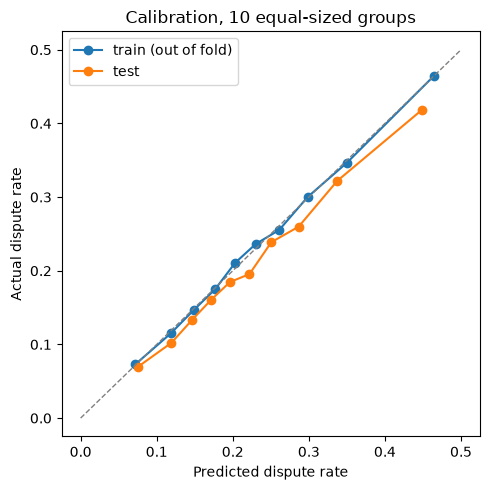

In [12]:
fig, ax = plt.subplots(figsize=(5, 5))
for label, y, p in [("train (out of fold)", y_train, risk_train["both"]), ("test", y_test, risk_test["both"])]:
    actual, predicted = calibration_curve(y, p, n_bins=10, strategy="quantile")
    ax.plot(predicted, actual, marker="o", label=label)
ax.plot([0, 0.5], [0, 0.5], color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Predicted dispute rate")
ax.set_ylabel("Actual dispute rate")
ax.set_title("Calibration, 10 equal-sized groups")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES + "calibration.png", dpi=150)
plt.show()

In [13]:
actual, predicted = calibration_curve(y_test, risk_test["both"], n_bins=10, strategy="quantile")
pd.DataFrame({"predicted": predicted, "actual": actual, "gap": predicted - actual}).round(3)

,predicted,actual,gap
0,0.075,0.069,0.006
1,0.119,0.102,0.017
2,0.147,0.133,0.013
3,0.171,0.160,0.011
4,0.196,0.185,0.012
5,0.222,0.195,0.026
6,0.251,0.239,0.012
7,0.287,0.260,0.027
8,0.337,0.322,0.015
9,0.448,0.418,0.030


After the rescaling the train scores average 23.2% for all three models, the actual rate, and on the chart the ten train groups of the combined model sit on the line.

On test the combined model predicts 22.5% on average and 20.8% were disputed, so it runs 1.7 points high, and all ten groups are high, by 0.6 to 3.0 points. The rescaling was fitted on train and the dispute rate fell after that. The first project's model had the same kind of gap, 19.4% predicted against 17.0% actual. A team that shows the score as a probability would refit the rescaling on its most recent months, and the review list would stay the same.

## Who gets reviewed

### Complaints without a narrative

In [14]:
everything = pd.read_parquet("../data/complaints.parquet", columns=[
    "Date received", "Submitted via", "Consumer complaint narrative", "Consumer disputed?"])
window = everything[everything["Consumer disputed?"].isin(["Yes", "No"])
                    & everything["Date received"].between("2016-10-01", "2017-02-28")]
has_text = window["Consumer complaint narrative"].notna()
disputed = window["Consumer disputed?"] == "Yes"
len(window), has_text.sum(), has_text.mean(), disputed[has_text].mean(), disputed[~has_text].mean()

(87439,
 np.int64(37405),
 np.float64(0.42778394080444654),
 np.float64(0.20839459965245288),
 np.float64(0.14188351920693928))

In [15]:
window.assign(has_text=has_text).groupby("Submitted via", observed=True)["has_text"].agg(["size", "mean"]).round(3)

,size,mean
Submitted via,,
Email,1,0.000
Fax,1004,0.000
Phone,4478,0.000
Postal mail,4129,0.000
Referral,9148,0.000
Web,68679,0.545


Of the 87,439 complaints with a dispute label in the test months, 37,405 have a narrative (42.8%). The other 50,034 get no text score. Complaints by phone, post, fax and referral never have a narrative, and 45.5% of web complaints don't have one either. Complaints without a narrative were disputed 14.2% of the time, against 20.8% for those with one.

So the combined model can rank less than half of the complaints, and the rest only have the fields. The public file has a narrative only when the consumer agreed to publish it, and those consumers dispute more often. Whether the text model would score the other consumers' complaints as well can't be tested with this data.

### Short narratives

In [16]:
train_narratives, narratives = time_split(load_text())
who = test[["complaint_id", "disputed"]].merge(narratives[["complaint_id", "tags", "text"]], on="complaint_id")
who["words"] = who["text"].str.split().str.len()
who["length"] = pd.qcut(who["words"], 4)
who["predicted"] = risk_test["both"]
who["on_fields_list"] = top_fields
who["on_combined_list"] = top_both

summary = {"narratives": ("disputed", "size"), "dispute_rate": ("disputed", "mean"), "predicted": ("predicted", "mean"),
           "on_fields_list": ("on_fields_list", "mean"), "on_combined_list": ("on_combined_list", "mean")}
who.groupby("length", observed=True).agg(**summary).round(3)

,narratives,dispute_rate,predicted,on_fields_list,on_combined_list
length,,,,,
"(1.999, 69.0]",9401,0.159,0.187,0.090,0.037
"(69.0, 133.0]",9313,0.195,0.207,0.095,0.059
"(133.0, 250.0]",9357,0.212,0.232,0.106,0.102
"(250.0, 837.0]",9334,0.268,0.275,0.108,0.202


In [17]:
who[who["on_combined_list"]].groupby("length", observed=True)["disputed"].agg(["size", "mean"]).round(3)

,size,mean
length,,
"(1.999, 69.0]",351,0.368
"(69.0, 133.0]",551,0.385
"(133.0, 250.0]",953,0.404
"(250.0, 837.0]",1885,0.445


The combined list leans towards long narratives. A narrative in the longest quarter (more than 250 words) is on it 20.2% of the time, and one in the shortest quarter (69 words or fewer) 3.7% of the time. The fields don't know the length, and the fields list takes 9.0% to 10.8% of each quarter.

The lean follows the dispute rates, which go from 15.9% in the shortest quarter to 26.8% in the longest, and the predicted rates go the same way, from 18.7% to 27.5%. Short narratives aren't scored below their actual rate. The gap between predicted and actual is largest for them, at 2.8 points. The short narratives that do make the list were disputed 36.8% of the time, against 44.5% for the long ones.

It still means that a consumer who writes 69 words or fewer is reviewed about a fifth as often as one who writes more than 250, while 15.9% of the short narratives end in a dispute.

### Older Americans and servicemembers

In [18]:
who.groupby("tags").agg(**summary).round(3)

,narratives,dispute_rate,predicted,on_fields_list,on_combined_list
tags,,,,,
None,31610,0.209,0.226,0.102,0.101
Older American,2940,0.205,0.225,0.093,0.095
"Older American, Servicemember",319,0.176,0.235,0.176,0.119
Servicemember,2536,0.207,0.215,0.072,0.086


In [19]:
train_narratives.groupby("tags")["disputed"].agg(["size", "mean"]).round(3)

,size,mean
tags,,
None,93260,0.234
Older American,10185,0.223
"Older American, Servicemember",1334,0.249
Servicemember,7477,0.217


Older Americans are on the combined list about as often as untagged consumers (9.5% against 10.1%) and dispute about as often (20.5% against 20.9%).

Servicemembers are on it less often, 8.6%, although in the test months they disputed at the same rate as untagged consumers (20.7%). In train they disputed less often, 21.7% against 23.4%, and the tag is one of the fields, so the models learned to score them a little lower. With the fields alone servicemembers are on the list 7.2% of the time, so the text narrows the gap without closing it. A team using the list would want to keep an eye on this group. The 319 complaints with both tags are too few to read much into.

## Scored test set for Power BI

One row per complaint and model for the Power BI page, with the rescaled score and the tenth of the ranking the complaint falls in. Decile 1 has the highest scores.

In [20]:
frames = []
for number, name in enumerate(MODELS, start=1):
    position = test[name].rank(method="first", ascending=False)
    frames.append(test[["complaint_id", "date_received", "product", "company", "disputed"]].assign(
        model=LABELS[name], model_no=number, risk=risk_test[name],
        decile=np.ceil(position / len(test) * 10).astype(int)))
by_model = pd.concat(frames)
by_model.to_csv("../data/scored_test_by_model.csv", index=False)
by_model.shape

(112215, 9)

In [21]:
by_model[by_model["decile"] == 1].groupby("model", sort=False)["disputed"].agg(["size", "mean"]).round(3)

,size,mean
model,,
fields,3740,0.321
text,3740,0.393
fields and text score,3740,0.418


For each model, decile 1 is the same 3,740 complaints as the top 10% above, with 32.1%, 39.3% and 41.8% of them disputed.